# Stopped clean-win bonus: partial results

Six pilots completed; pilot 007 stopped at 38 epochs. This is not a completed population comparison. Confirmation did not run.

# Compare notebook 05 populations

This report compares a named experiment with its recorded baseline. Start with the [experiment index](../docs/pilot_experiments.md). **Run All is read-only: it does not train, load models, use the GPU, or rerun simulations.** Use the project `.venv` kernel. Rerun it to refresh results while training continues, then save the notebook to retain its tables and embedded plots.

Choose `EXPERIMENT` below from `configs/pilot_experiments.json`, or override `EXPERIMENT_JOB` to inspect another prepared experiment. Its recorded plan supplies the baseline and training directories. Experiments run separately; this report never starts or resumes them.

The tables and plots use the same recorded metrics as notebook 05: checkpoint selection, test competence, behaviour, skill fractions, common validation reward components, learning curves, clean-win intervals and behaviour scatter. Results appear only when a pilot finishes training and testing; partial learning curves are labelled.

The original test has already informed this experiment, so it is now a **development comparison**. The separate **fresh confirmation** section becomes available after both populations have been evaluated on the predeclared new cases. Neither report changes checkpoints.


Set `BVR_COMPARISON_EXPORT=1` before running the report to also export its figures as PNG and PDF under the experiment's `plots/` directory. The default reads results without exporting files; neither mode changes training artifacts.


In [1]:
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "bvr_behavior_prediction").is_dir()
)
# Choose a name from the registry. BVR_COMPARISON_JOB also accepts an unregistered job.
registry = json.loads((REPO_ROOT / "configs/pilot_experiments.json").read_text(encoding="utf8"))
EXPERIMENT = os.getenv("BVR_COMPARISON_EXPERIMENT", registry["default_experiment"])
EXPERIMENT_JOB = Path(os.getenv(
    "BVR_COMPARISON_JOB", str(REPO_ROOT / registry["experiments"][EXPERIMENT]["job"])
)).resolve()


def read_json(path):
    # A running process may be updating a manifest at the instant it is read.
    for attempt in range(3):
        try:
            return json.loads(path.read_text(encoding="utf8"))
        except json.JSONDecodeError:
            if attempt == 2:
                raise
            time.sleep(0.1)


def read_metrics(path):
    if not path.exists():
        return pd.DataFrame()
    lines = path.read_text(encoding="utf8").splitlines()
    rows = []
    for index, line in enumerate(lines):
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            if index != len(lines) - 1:
                raise  # Only an incomplete final append is expected during training.
    return pd.DataFrame(rows)


plan = read_json(EXPERIMENT_JOB / "experiment.json")
if plan.get("intervention") == "tactical_adaptation":
    raise ValueError("Use notebooks/07_tactical_adaptation.ipynb for matched tactical-opponent comparisons.")
EXPERIMENT_LABEL = plan.get("experiment_label", "Lower learning rate")
RUNS = {
    "Baseline": Path(plan["baseline"]),
    EXPERIMENT_LABEL: Path(plan["training_output"]),
}
status = read_json(EXPERIMENT_JOB / "status.json")
print(f"Experiment status: {status['status']}")
if "error" in status:
    print(status["error"])
print(plan.get("change_description", f"Learning rate: {plan['baseline_learning_rate']} -> {plan['learning_rate']}"))
if "recovery" in plan:
    recovery = plan["recovery"]
    print("Preserved completed pilots:", ", ".join(recovery["reused_pilots"]))
    print("Train from original seeds:", ", ".join(recovery["restart_from_scratch"]))
    print("The failed attempt is preserved at:", recovery["previous_job"])
if "reward_intervention" in plan:
    display(Markdown("**Reward intervention**"))
    display(pd.Series(plan["reward_intervention"]))
print(f"Experiment: {EXPERIMENT_JOB}")
print("This report is a snapshot. Run All again to refresh it.")


# Optional standalone figures for presentations; no simulator/model execution.
EXPORT_PLOTS = os.getenv("BVR_COMPARISON_EXPORT", "0") == "1"
PLOT_DIRECTORY = EXPERIMENT_JOB / "plots"


def show_plot(figure, name):
    if EXPORT_PLOTS:
        PLOT_DIRECTORY.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            figure.savefig(PLOT_DIRECTORY / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)


if EXPORT_PLOTS:
    print(f"Standalone PNG/PDF figures: {PLOT_DIRECTORY}")


Experiment status: stopped
Only a +250 terminal clean-win bonus was added to each pilot's existing event reward.
Preserved completed pilots: pilot_001, pilot_002, pilot_003, pilot_004, pilot_005, pilot_006
Train from original seeds: pilot_007, pilot_008, pilot_009, pilot_010
The failed attempt is preserved at: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\rl_pilot_experiments\20261010T114552_188643Z_clean_win_bonus


**Reward intervention**

clean_win_bonus                                                      250.0
condition                Once at episode end, own aircraft alive and co...
original_coefficients                                            unchanged
selection                Maximum own validation return, including the n...
benchmark                Original common CombatReward v2; bonus exclude...
dtype: object

Experiment: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\rl_pilot_experiments\20261010T194825_532536Z_clean_win_bonus_recovery
This report is a snapshot. Run All again to refresh it.


## Progress and saved reward preferences

Matching pilot IDs retain the same original event coefficients. The `terminal_clean_win_bonus` column records any extra end-of-episode reward; zero means the original reward recipe. These are coefficients, not cumulative reward contributions.

When reward recipes differ, own training and validation returns are not directly comparable between runs. Use the common benchmark and outcome tables to judge performance. Individual reward returns are also not a common score across different pilot preferences.


In [2]:
batches = {
    name: read_json(directory / "pilots.json")
    if (directory / "pilots.json").exists() else {"pilots": []}
    for name, directory in RUNS.items()
}
metrics_by_run = {}
progress_rows, reward_rows, completed_rows = [], [], []
for name, batch in batches.items():
    metrics_by_run[name] = {}
    for pilot in batch["pilots"]:
        pilot_id = pilot["pilot_id"]
        directory = RUNS[name] / pilot.get("output_dir", pilot_id)
        metrics = read_metrics(directory / "training_metrics.jsonl")
        metrics_by_run[name][pilot_id] = metrics
        progress_rows.append({
            "run": name, "pilot_id": pilot_id, "status": pilot["status"],
            "epochs_finished": int(metrics["epoch"].max()) if not metrics.empty else 0,
            "epochs_planned": plan["epochs_per_pilot"],
        })
        reward_rows.append({
            "run": name, "pilot_id": pilot_id, "seed": pilot["seed"],
            "terminal_clean_win_bonus": pilot["reward"]["parameters"].get("clean_win_bonus", 0.0),
            **pilot["reward"]["parameters"]["weights"],
        })
        if pilot["status"] == "completed":
            completed_rows.append({"run": name, **pilot})

progress = pd.DataFrame(progress_rows)
display(progress)
display(pd.DataFrame(reward_rows).set_index(["run", "pilot_id"]))
print("Completed pilots:", {
    name: sum(p["status"] == "completed" for p in batch["pilots"])
    for name, batch in batches.items()
})


,run,pilot_id,status,epochs_finished,epochs_planned
0,Baseline,pilot_001,completed,150,150
1,Baseline,pilot_002,completed,150,150
2,Baseline,pilot_003,completed,150,150
3,Baseline,pilot_004,completed,150,150
4,Baseline,pilot_005,completed,150,150
5,Baseline,pilot_006,completed,150,150
6,Baseline,pilot_007,completed,150,150
7,Baseline,pilot_008,completed,150,150
8,Baseline,pilot_009,completed,150,150
9,Baseline,pilot_010,completed,150,150


seed  terminal_clean_win_bonus     crashed  \
run             pilot_id                                                
Baseline        pilot_001     7                       0.0 -333.906593   
                pilot_002     7                       0.0 -430.782955   
                pilot_003     7                       0.0 -366.812282   
                pilot_004     7                       0.0 -333.242475   
                pilot_005     7                       0.0 -401.126196   
                pilot_006     7                       0.0 -384.427212   
                pilot_007     7                       0.0 -347.625674   
                pilot_008     7                       0.0 -381.162634   
                pilot_009     7                       0.0 -354.792252   
                pilot_010     7                       0.0 -321.989539   
Clean-win bonus pilot_001     7                     250.0 -333.906593   
                pilot_002     7                     250.0 -430.782955   
                pilot_003     7                     250.0 -366.812282   
                pilot_004     7                     250.0 -333.242475   
                pilot_005     7                     250.0 -401.126196   
                pilot_006     7                     250.0 -384.427212   
                pilot_007     7                     250.0 -347.625674   
                pilot_008     7                     250.0 -381.162634   
                pilot_009     7                     250.0 -354.792252   
                pilot_010     7                     250.0 -321.989539   

                            shot_down  ground_clearance  target_lock_acquired  \
run             pilot_id                                                        
Baseline        pilot_001 -384.168234              0.02              1.394736   
                pilot_002 -382.442109              0.02              1.853530   
                pilot_003 -440.427412              0.02              1.263329   
                pilot_004 -420.804194              0.02              0.087608   
                pilot_005 -394.431044              0.02              0.378943   
                pilot_006 -325.098271              0.02              0.624733   
                pilot_007 -429.037127              0.02              0.014725   
                pilot_008 -364.688821              0.02              0.229060   
                pilot_009 -366.963090              0.02              0.607900   
                pilot_010 -414.909077              0.02              0.562768   
Clean-win bonus pilot_001 -384.168234              0.02              1.394736   
                pilot_002 -382.442109              0.02              1.853530   
                pilot_003 -440.427412              0.02              1.263329   
                pilot_004 -420.804194              0.02              0.087608   
                pilot_005 -394.431044              0.02              0.378943   
                pilot_006 -325.098271              0.02              0.624733   
                pilot_007 -429.037127              0.02              0.014725   
                pilot_008 -364.688821              0.02              0.229060   
                pilot_009 -366.963090              0.02              0.607900   
                pilot_010 -414.909077              0.02              0.562768   

                           fired_with_lock  incoming_missile_avoided  \
run             pilot_id                                               
Baseline        pilot_001         0.188355                 14.634335   
                pilot_002         1.287730                 12.341424   
                pilot_003         1.516175                  5.317890   
                pilot_004         0.308579                 10.245734   
                pilot_005         0.259843                  7.135574   
                pilot_006         1.664520                 12.071465   
                pilot_007         1.573849                  9

Completed pilots: {'Baseline': 10, 'Clean-win bonus': 6}


## Checkpoint selection and original test competence

These reproduce notebook 05's first two result tables, with a run column. **Selection return** uses each pilot's own reward. **Benchmark return** uses the common reward on validation scenarios. The second table reports the separate original test cases, now used for development comparison.

A clean win means a confirmed missile elimination while surviving. The shared outcome score is +100 for a clean win, 0 for survival without a confirmed elimination, -50 for mutual destruction and -100 for own loss with the opponent alive. Confidence intervals describe scenario uncertainty, not variation between repeated training seeds. Missing results mean pending, not zero.

For the clean-win experiment, selection return includes the terminal bonus. Benchmark returns and outcome definitions remain identical for both populations and exclude that bonus.


In [3]:
summary = pd.DataFrame(completed_rows)
test_summary = pd.DataFrame([
    {"run": pilot["run"], "pilot_id": pilot["pilot_id"], **pilot["test"]}
    for pilot in completed_rows if "test" in pilot
])
COMPETENCE_COLUMNS = [
    "run", "pilot_id", "scenarios", "clean_win_rate", "clean_win_ci95",
    "mutual_destruction_rate", "survival_rate", "elimination_rate", "outcome_score",
]
BEHAVIOUR_COLUMNS = [
    "run", "pilot_id", "mean_missiles_launched", "mean_missiles_avoided",
    "mean_threatened_seconds", "mean_duration_seconds",
]


def show_competence(frame):
    if frame.empty:
        print("No completed evaluations yet.")
    else:
        display(frame[COMPETENCE_COLUMNS].sort_values(
            ["run", "clean_win_rate", "outcome_score"], ascending=[True, False, False]
        ))


if not summary.empty:
    display(summary[[
        "run", "pilot_id", "selection_return", "benchmark_return", "checkpoint"
    ]])
show_competence(test_summary)


,run,pilot_id,selection_return,benchmark_return,checkpoint
0,Baseline,pilot_001,94.168174,223.8028,pilot_001/best_model.pt
1,Baseline,pilot_002,132.789859,255.4784,pilot_002/best_model.pt
2,Baseline,pilot_003,54.834285,225.6876,pilot_003/best_model.pt
3,Baseline,pilot_004,88.001477,233.2000,pilot_004/best_model.pt
4,Baseline,pilot_005,62.512347,215.7868,pilot_005/best_model.pt
5,Baseline,pilot_006,124.527706,222.1012,pilot_006/best_model.pt
6,Baseline,pilot_007,110.771459,246.5704,pilot_007/best_model.pt
7,Baseline,pilot_008,102.788175,237.1956,pilot_008/best_model.pt
8,Baseline,pilot_009,102.727514,240.4412,pilot_009/best_model.pt
9,Baseline,pilot_010,97.654367,232.0696,pilot_010/best_model.pt


,run,pilot_id,scenarios,clean_win_rate,clean_win_ci95,mutual_destruction_rate,survival_rate,elimination_rate,outcome_score
1,Baseline,pilot_002,100,0.60,"[0.5020025867910618, 0.6905987135675411]",0.23,0.73,0.83,44.5
4,Baseline,pilot_005,100,0.56,"[0.4622810465167699, 0.6532797336983921]",0.20,0.67,0.76,33.0
0,Baseline,pilot_001,100,0.54,"[0.44264860323368227, 0.6343919169097589]",0.27,0.64,0.81,31.5
2,Baseline,pilot_003,100,0.53,"[0.4328885697009936, 0.6248918204065872]",0.21,0.73,0.74,36.5
8,Baseline,pilot_009,100,0.52,"[0.4231657776522397, 0.615354482419481]",0.23,0.67,0.75,30.5
7,Baseline,pilot_008,100,0.48,"[0.384645517580519, 0.5768342223477603]",0.27,0.66,0.75,27.5
9,Baseline,pilot_010,100,0.46,"[0.36560808309024106, 0.5573513967663177]",0.21,0.74,0.67,30.5
6,Baseline,pilot_007,100,0.45,"[0.3561453797951198, 0.5475539700255787]",0.23,0.71,0.68,27.5
5,Baseline,pilot_006,100,0.45,"[0.3561453797951198, 0.5475539700255787]",0.14,0.63,0.59,15.0
3,Baseline,pilot_004,100,0.41,"[0.3186731302113651, 0.5079856994658921]",0.23,0.70,0.64,22.5


## Original test behaviour and common validation components

Missile use, threat exposure and skill fractions describe observed behaviour; they are not measures of competence by themselves. The final table contains **mean cumulative points per flight under the common validation reward**, exactly as in notebook 05. Each row sums to that pilot's validation benchmark return. These values are not reward coefficients.


In [4]:
def show_behaviour(frame):
    if frame.empty:
        print("No completed behaviour evaluations yet.")
        return
    display(frame[BEHAVIOUR_COLUMNS])
    skills = pd.DataFrame([
        {"run": row["run"], "pilot_id": row["pilot_id"], **row["skill_decision_fractions"]}
        for _, row in frame.iterrows()
    ]).set_index(["run", "pilot_id"]).fillna(0.0)
    display(skills)


show_behaviour(test_summary)
if completed_rows:
    print("Common validation reward components: mean points per flight")
    display(pd.DataFrame([
        {"run": pilot["run"], "pilot_id": pilot["pilot_id"],
         **pilot["benchmark_component_means"]}
        for pilot in completed_rows
    ]).set_index(["run", "pilot_id"]))


,run,pilot_id,mean_missiles_launched,mean_missiles_avoided,mean_threatened_seconds,mean_duration_seconds
0,Baseline,pilot_001,1.57,2.94,66.902,76.569
1,Baseline,pilot_002,1.75,3.67,72.970,83.879
2,Baseline,pilot_003,1.11,3.71,72.769,84.237
3,Baseline,pilot_004,1.07,3.40,72.419,84.772
4,Baseline,pilot_005,1.40,3.43,69.690,80.535
5,Baseline,pilot_006,1.05,3.08,67.810,80.247
6,Baseline,pilot_007,1.20,3.65,72.212,83.990
7,Baseline,pilot_008,1.25,3.28,69.721,81.355
8,Baseline,pilot_009,1.66,3.26,70.228,81.482
9,Baseline,pilot_010,1.30,3.71,74.184,85.999


abort_support  beam_missile_left  \
run             pilot_id                                      
Baseline        pilot_001       0.000780           0.001300   
                pilot_002       0.070640           0.000000   
                pilot_003       0.000118           0.002720   
                pilot_004       0.092960           0.000000   
                pilot_005       0.000000           0.000000   
                pilot_006       0.001366           0.001117   
                pilot_007       0.000474           0.000000   
                pilot_008       0.007583           0.000000   
                pilot_009       0.014298           0.000000   
                pilot_010       0.054564           0.000000   
Clean-win bonus pilot_001       0.000126           0.000000   
                pilot_002       0.000000           0.000131   
                pilot_003       0.012429           0.000000   
                pilot_004       0.004142           0.000000   
                pilot_005       0.010179           0.002486   
                pilot_006       0.001523           0.009138   

                           beam_missile_right  beam_target_left  \
run             pilot_id                                          
Baseline        pilot_001            0.004811          0.071382   
                pilot_002            0.006292          0.035498   
                pilot_003            0.006386          0.007923   
                pilot_004            0.004936          0.067576   
                pilot_005            0.006920          0.020388   
                pilot_006            0.000497          0.088641   
                pilot_007            0.002017          0.045433   
                pilot_008            0.008562          0.020915   
                pilot_009            0.008921          0.066357   
                pilot_010            0.000232          0.042053   
Clean-win bonus pilot_001            0.004400          0.000251   
                pilot_002            0.000000          0.063783   
                pilot_003            0.006732          0.000000   
                pilot_004            0.009665          0.219782   
                pilot_005            0.000000          0.010889   
                pilot_006            0.002343          0.048032   

                           beam_target_right  crank_target_left  \
run             pilot_id                                          
Baseline        pilot_001           0.017293           0.174750   
                pilot_002           0.096047           0.177609   
                pilot_003           0.031220           0.111755   
                pilot_004           0.039018           0.087202   
                pilot_005           0.121216           0.187817   
                pilot_006           0.033520           0.217505   
                pilot_007           0.035587           0.109371   
                pilot_008           0.054672           0.174658   
                pilot_009           0.123671           0.191617   
                pilot_010           0.051437           0.099977   
Clean-win bonus pilot_001           0.020116           0.277596   
                pilot_002           0.087701           0.231996   
                pilot_003           0.054894           0.190704   
                pilot_004           0.228693           0.110581   
                pilot_005           0.150195           0.184756   
                pilot_006           0.073571           0.183458   

                           crank_target_right  decelerate_to_speed  \
run             pilot_id                                             
Baseline        pilot_001            0.149395             0.007151   
                pilot_002            0.018402             0.000000   
                pilot_003            0.034886             0.000000   
                pilot_004            0.028323             0.000000   
                pilot_005            0.039046             

Common validation reward components: mean points per flight


crashed  fired_with_lock  fired_without_lock  \
run             pilot_id                                                  
Baseline        pilot_001      0.0            15.52                 0.0   
                pilot_002      0.0            17.12                 0.0   
                pilot_003      0.0            11.20                 0.0   
                pilot_004      0.0            11.52                 0.0   
                pilot_005      0.0            11.68                 0.0   
                pilot_006      0.0            11.04                 0.0   
                pilot_007      0.0            13.28                 0.0   
                pilot_008      0.0            12.48                 0.0   
                pilot_009      0.0            12.96                 0.0   
                pilot_010      0.0            12.80                 0.0   
Clean-win bonus pilot_001      0.0            12.64                 0.0   
                pilot_002      0.0            11.68                 0.0   
                pilot_003      0.0            12.96                 0.0   
                pilot_004      0.0            13.92                 0.0   
                pilot_005      0.0            13.28                 0.0   
                pilot_006      0.0            10.08                 0.0   

                           ground_clearance  missile_avoided  \
run             pilot_id                                       
Baseline        pilot_001            1.4028             58.0   
                pilot_002            1.4784             64.0   
                pilot_003            1.4476             61.2   
                pilot_004            1.4400             60.4   
                pilot_005            1.4668             58.8   
                pilot_006            1.4612             61.6   
                pilot_007            1.5304             68.0   
                pilot_008            1.4356             56.4   
                pilot_009            1.4812             61.2   
                pilot_010            1.5096             62.0   
Clean-win bonus pilot_001            1.4804             60.8   
                pilot_002            1.4028             52.8   
                pilot_003            1.4828             59.2   
                pilot_004            1.4824             63.2   
                pilot_005            1.4164             56.0   
                pilot_006            1.4896             61.6   

                           opponent_destroyed  shot_down  target_locked  
run             pilot_id                                                 
Baseline        pilot_001               210.0      -63.0           1.88  
                pilot_002               225.0      -54.0           1.88  
                pilot_003               210.0      -60.0           1.84  
                pilot_004               215.0      -57.0           1.84  
                pilot_005               205.0      -63.0           1.84  
                pilot_006               200.0      -54.0           2.00  
                pilot_007               210.0      -48.0           1.76  
                pilot_008               225.0      -60.0           1.88  
                pilot_009               220.0      -57.0           1.80  
                pilot_010               205.0      -51.0           1.76  
Clean-win bonus pilot_001               190.0      -60.0           2.12  
                pilot_002               220.0      -63.0           1.88  
                pilot_003               210.0      -54.0           1.84  
                pilot_004               225.0      -54.0           1.92  
                pilot_005               215.0      -66.0           1.92  
                pilot_006               205.0      -54.0           1.96

## Learning curves, including pilots still training

Each row compares matching reward preferences. Colours distinguish runs; line styles distinguish training, validation and best validation return. The right panel shows the actor and critic losses in their learning units. Partial curves are labelled with their last completed epoch. Lower loss alone does not establish better combat performance.

When comparing selected-skill probabilities with the older unmasked baseline, policy loss, entropy and KL use different action definitions, so their absolute values are not directly comparable. The skill-conditioned experiment retains the selected-skill objective and changes the parameter predictor architecture. Value loss retains its definition, but each policy collects different flights. Judge improvement by the matched outcome evaluations.

For reward interventions, own returns and critic losses use different reward targets. Their absolute values do not measure comparative competence; use the common outcome evaluations.


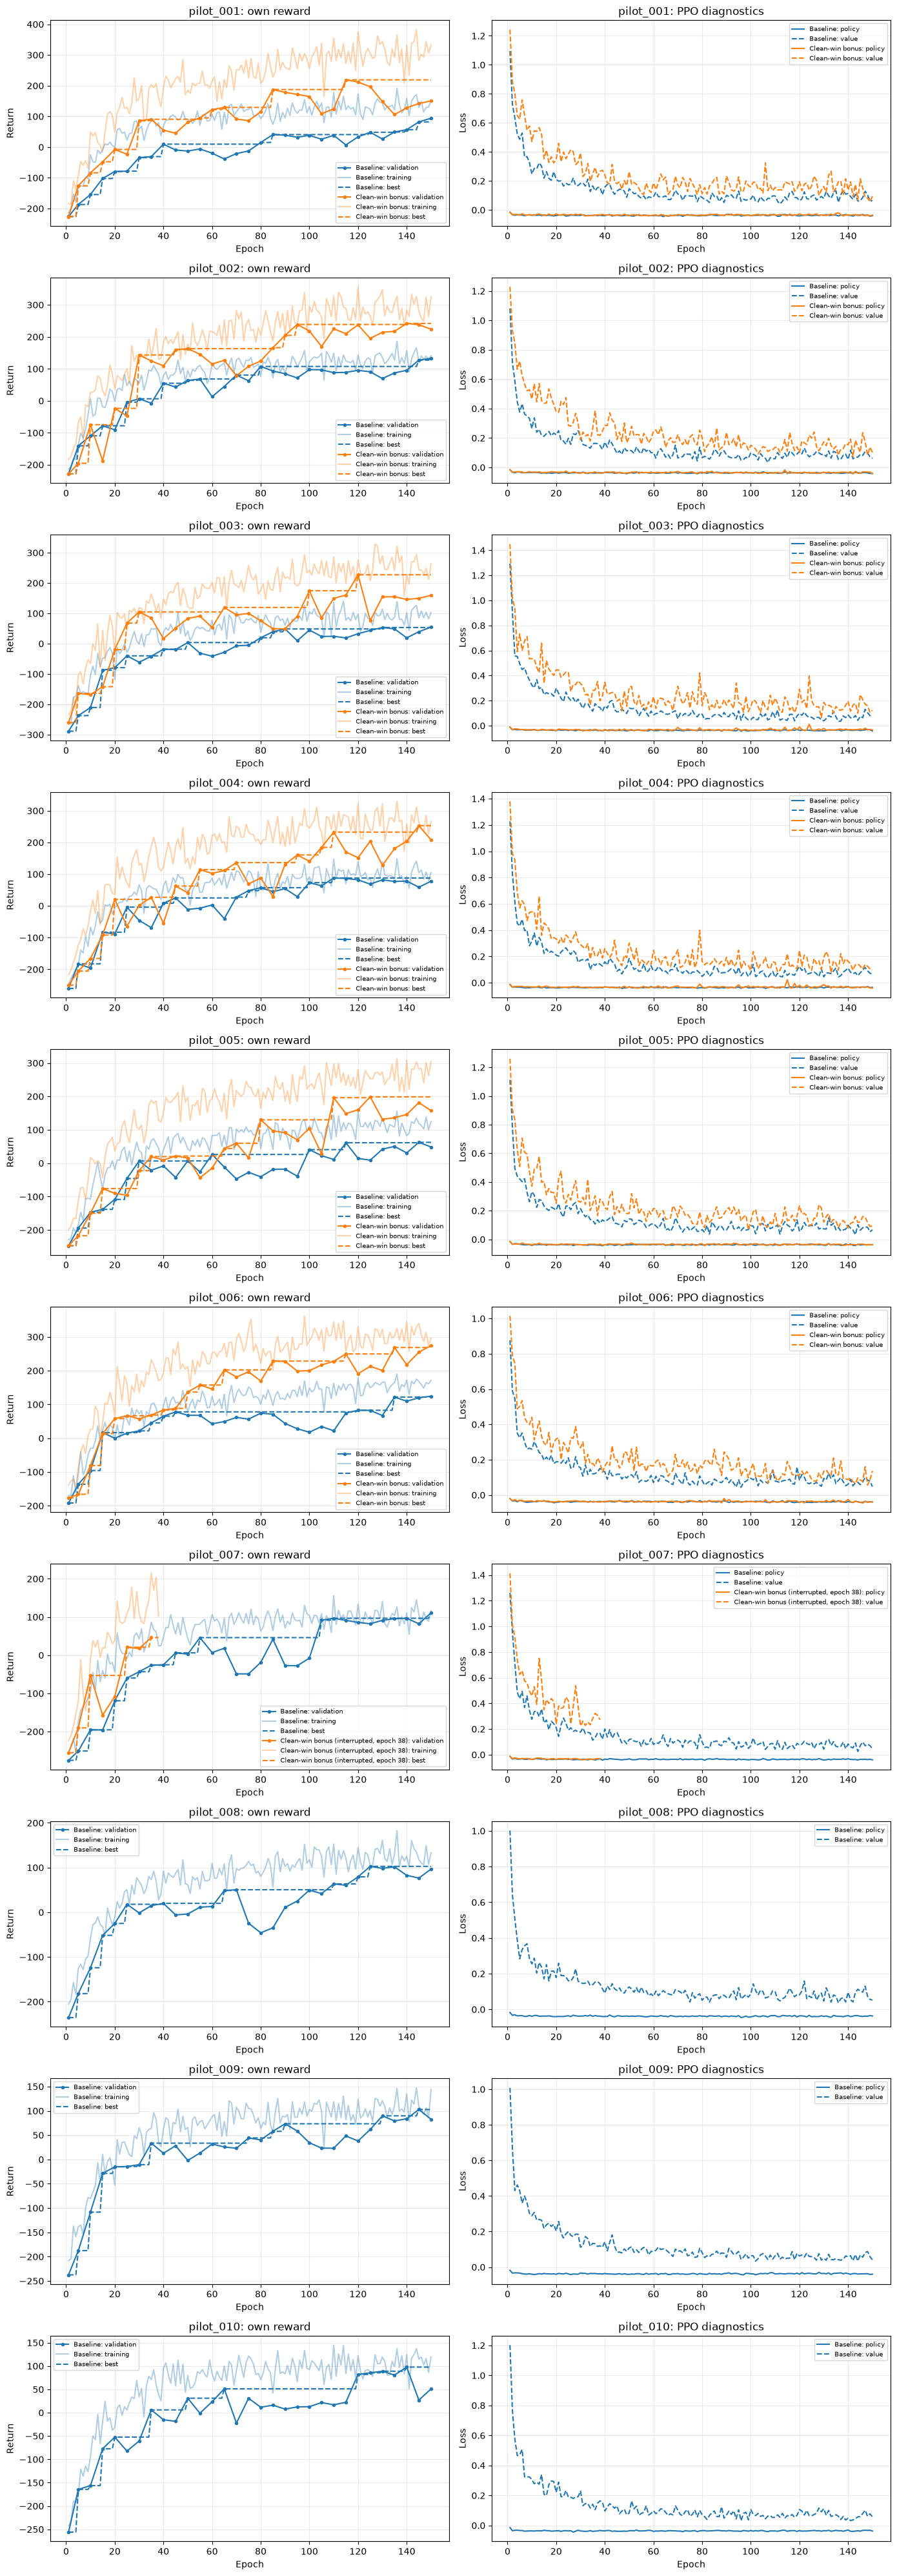

In [5]:
COLOURS = {"Baseline": "tab:blue", EXPERIMENT_LABEL: "tab:orange"}
pilot_ids = sorted({
    pilot_id for metrics in metrics_by_run.values()
    for pilot_id, frame in metrics.items() if not frame.empty
})
if pilot_ids:
    figure, axes = plt.subplots(len(pilot_ids), 2, figsize=(14, 4 * len(pilot_ids)), squeeze=False)
    for row, pilot_id in enumerate(pilot_ids):
        for name, records in metrics_by_run.items():
            metrics = records.get(pilot_id, pd.DataFrame())
            if metrics.empty:
                continue
            pilot_status = next(p["status"] for p in batches[name]["pilots"] if p["pilot_id"] == pilot_id)
            label = name
            if pilot_status != "completed":
                label += f" ({pilot_status}, epoch {int(metrics['epoch'].max())})"
            evaluated = metrics[metrics["evaluation_performed"] == 1]
            colour = COLOURS[name]
            axes[row, 0].plot(evaluated["epoch"], evaluated["mean_return"],
                              marker=".", color=colour, label=f"{label}: validation")
            axes[row, 0].plot(metrics["epoch"], metrics["training_mean_return"],
                              alpha=0.35, color=colour, label=f"{label}: training")
            axes[row, 0].plot(metrics["epoch"], metrics["best_return"],
                              linestyle="--", color=colour, label=f"{label}: best")
            if {"policy_loss", "value_loss"}.issubset(metrics.columns):
                axes[row, 1].plot(metrics["epoch"], metrics["policy_loss"],
                                  color=colour, label=f"{label}: policy")
                axes[row, 1].plot(metrics["epoch"], metrics["value_loss"],
                                  linestyle="--", color=colour, label=f"{label}: value")
            else:
                axes[row, 1].plot(metrics["epoch"], metrics["loss"], color=colour, label=label)
        axes[row, 0].set(title=f"{pilot_id}: own reward", xlabel="Epoch", ylabel="Return")
        axes[row, 1].set(title=f"{pilot_id}: PPO diagnostics", xlabel="Epoch", ylabel="Loss")
        for axis in axes[row]:
            axis.grid(alpha=0.25)
            axis.legend(fontsize=7)
    figure.tight_layout()
    show_plot(figure, "learning_curves")
else:
    print("No recorded epochs yet.")


## Original test plots

These show the same clean-win intervals and behaviour scatter as notebook 05, with both runs on the same axes. A missing bar is a pending result, not a zero clean-win rate. The Wilson intervals are per pilot and run; use the paired comparison below to assess changes on matching scenarios.


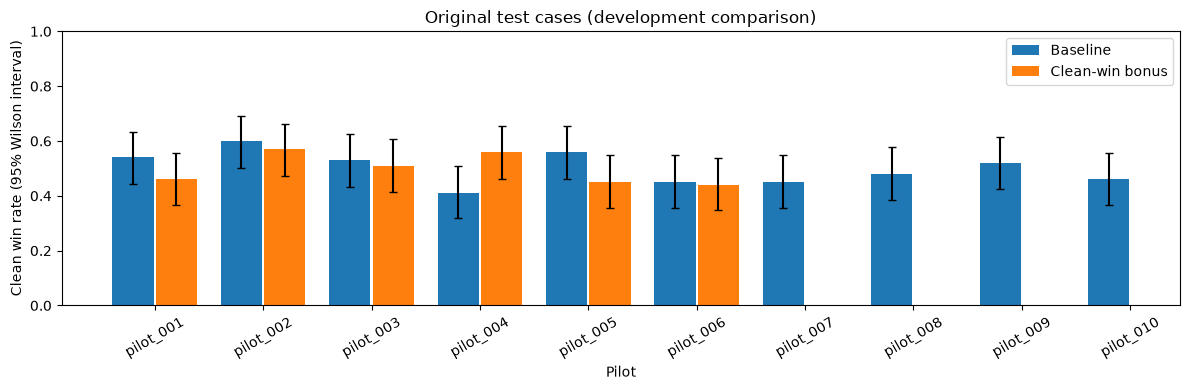

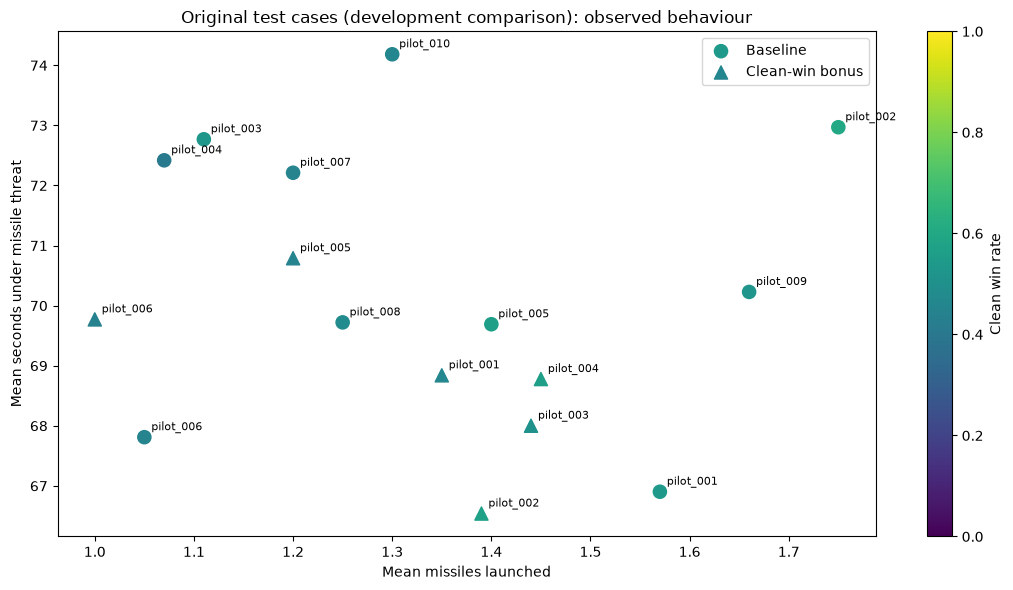

In [6]:
def plot_evaluation(frame, title, prefix):
    if frame.empty:
        print(f"{title}: no completed evaluations yet.")
        return
    pilot_ids = sorted(frame["pilot_id"].unique())
    positions = np.arange(len(pilot_ids))
    figure, axis = plt.subplots(figsize=(12, 4))
    for offset, (name, colour) in zip((-0.2, 0.2), COLOURS.items()):
        data = frame[frame["run"] == name]
        if data.empty:
            continue
        x = np.asarray([pilot_ids.index(pilot_id) for pilot_id in data["pilot_id"]])
        rate = data["clean_win_rate"].to_numpy()
        bounds = np.asarray(data["clean_win_ci95"].tolist())
        errors = np.maximum(0, np.vstack((rate - bounds[:, 0], bounds[:, 1] - rate)))
        axis.bar(x + offset, rate, width=0.38, yerr=errors, capsize=3, color=colour, label=name)
    axis.set(xticks=positions, xticklabels=pilot_ids, ylim=(0, 1), xlabel="Pilot",
             ylabel="Clean win rate (95% Wilson interval)", title=title)
    axis.tick_params(axis="x", labelrotation=30)
    axis.legend()
    figure.tight_layout()
    show_plot(figure, f"{prefix}_clean_wins")

    figure, axis = plt.subplots(figsize=(11, 6))
    points = None
    for name, marker in zip(COLOURS, ("o", "^")):
        data = frame[frame["run"] == name].dropna(
            subset=["mean_missiles_launched", "mean_threatened_seconds"]
        )
        if data.empty:
            continue
        points = axis.scatter(
            data["mean_missiles_launched"], data["mean_threatened_seconds"],
            c=data["clean_win_rate"], vmin=0, vmax=1, s=90, cmap="viridis",
            marker=marker, label=name,
        )
        for _, pilot in data.iterrows():
            axis.annotate(pilot["pilot_id"],
                          (pilot["mean_missiles_launched"], pilot["mean_threatened_seconds"]),
                          xytext=(5, 5), textcoords="offset points", fontsize=8)
    axis.set(title=f"{title}: observed behaviour",
             xlabel="Mean missiles launched", ylabel="Mean seconds under missile threat")
    if points is not None:
        figure.colorbar(points, ax=axis, label="Clean win rate")
        axis.legend()
    figure.tight_layout()
    show_plot(figure, f"{prefix}_behaviour")


plot_evaluation(test_summary, "Original test cases (development comparison)", "development")


## Fresh confirmation: the same evaluation tables and plots

After training, the runner evaluates **both populations** on the predeclared fresh scenarios. This section reads those results as they arrive. It uses the same outcome definitions, behaviour measurements and plots as above. Until both populations finish, these are partial results; the final population comparison appears in the next section.


In [7]:
confirmation_rows = []
for population, name in (("baseline", "Baseline"), ("experiment", EXPERIMENT_LABEL)):
    for path in sorted((EXPERIMENT_JOB / "confirmation" / population).glob("*/evaluation.json")):
        evaluation = read_json(path)
        confirmation_rows.append({
            "run": name, "pilot_id": path.parent.name, **evaluation["summary"]
        })
confirmation_summary = pd.DataFrame(confirmation_rows)
print(f"Predeclared suite: {plan['confirmation']}")
show_competence(confirmation_summary)
show_behaviour(confirmation_summary)
plot_evaluation(confirmation_summary, "Fresh confirmation", "confirmation")


Predeclared suite: {'seed': 920000, 'scenarios': 300}
No completed evaluations yet.
No completed behaviour evaluations yet.
Fresh confirmation: no completed evaluations yet.


## Matched differences and overall result

The runner writes this comparison only after the relevant suite is complete for the whole population. The primary measure is the mean clean-win rate over all matching reward profiles, not the best pilot. Gained/lost wins count identical cases whose clean-win outcome changed.

The paired bootstrap resamples scenarios jointly across pilots; its interval measures scenario uncertainty. One training seed does not establish a robust improvement. Judge the fresh confirmation alongside survival and mutual destruction; do not select a checkpoint using it.


In [8]:
comparison_path = EXPERIMENT_JOB / "comparison.json"
if comparison_path.exists():
    comparison = read_json(comparison_path)
    aggregate_rows = []
    for suite, title in (
        ("existing_test", "Original test (development)"),
        ("fresh_confirmation", "Fresh confirmation"),
    ):
        if suite not in comparison:
            continue
        values = comparison[suite]
        display(Markdown(f"**{title}: paired changes**"))
        display(pd.DataFrame(values["pilots"]))
        aggregate_rows.append({
            "suite": title,
            "baseline_mean_clean_win_rate": values["baseline_mean_clean_win_rate"],
            "experiment_mean_clean_win_rate": values["experiment_mean_clean_win_rate"],
            "change_percentage_points": values["difference_percentage_points"],
            "paired_change_ci95_percentage_points":
                values["paired_scenario_bootstrap_ci95_percentage_points"],
        })
    display(pd.DataFrame(aggregate_rows))
    print(f"Report status: {comparison['status']}")
    print(f"Standalone report: {EXPERIMENT_JOB / 'comparison.html'}")
else:
    print("The full-population comparison will appear after all pilots finish training and testing.")
if "bounded_decision_criteria" in plan:
    display(Markdown("**Predeclared bounded experiment criteria**"))
    display(pd.Series(plan["bounded_decision_criteria"], name="criterion"))
    if comparison_path.exists() and "decision" in comparison:
        display(Markdown("**Final confirmation decision**"))
        decision = comparison["decision"]
        display(pd.Series(decision["checks"], name="passed"))
        print(decision["recommendation"])
        print(decision["limitation"])
    else:
        print("Decision pending: both populations must finish all fresh confirmation cases.")

print("Save this notebook after refreshing to retain the displayed tables and embedded figures.")


The full-population comparison will appear after all pilots finish training and testing.


**Predeclared bounded experiment criteria**

minimum_clean_win_gain_percentage_points                                                               3.0
minimum_ci_lower_bound_percentage_points_exclusive                                                     0.0
maximum_survival_drop_percentage_points                                                                2.0
maximum_mutual_destruction_increase_percentage_points                                                  2.0
training_runs_per_profile                                                                                1
next_step                                                Review this one comparison, then choose a popu...
Name: criterion, dtype: object

Decision pending: both populations must finish all fresh confirmation cases.
Save this notebook after refreshing to retain the displayed tables and embedded figures.


## Population outcomes and paired improvements

The stacked bars partition every flight into one of four outcomes. Population averages give each pilot equal weight. Compare populations **within** each suite; the two suites contain different scenarios.

The paired-change charts show which pilots improve or regress on the same cases. The interval in each title is for the **population mean change**, from the recorded paired scenario bootstrap. It does not measure variation across training seeds. Positive changes mean more clean wins; these plots do not select checkpoints.

In [9]:
if comparison_path.exists() and comparison.get("status") == "completed":
    suites = [
        ("existing_test", "Development cases", test_summary),
        ("fresh_confirmation", "Fresh confirmation", confirmation_summary),
    ]
    outcomes = [
        ("clean_win_rate", "Eliminate and survive", "#15803d", "white"),
        ("survived_without_elimination_rate", "Survive without elimination", "#60a5fa", "#111827"),
        ("mutual_destruction_rate", "Mutual destruction", "#f59e0b", "#111827"),
        ("loss_without_elimination_rate", "Own loss without opponent destruction", "#dc2626", "white"),
    ]
    figure, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    for axis, (key, title, frame) in zip(axes, suites):
        columns = [item[0] for item in outcomes]
        assert np.allclose(frame[columns].sum(axis=1), 1.0)
        means = frame.groupby("run")[columns].mean().reindex(list(RUNS)) * 100
        left = np.zeros(len(means))
        for column, label, colour, text_colour in outcomes:
            values = means[column].to_numpy()
            axis.barh(np.arange(len(means)), values, left=left, color=colour,
                      label=label, height=0.48, edgecolor="white")
            for row, value in enumerate(values):
                axis.text(left[row] + value / 2, row, f"{value:.1f}%",
                          ha="center", va="center", color=text_colour, fontsize=10)
            left += values
        axis.set(yticks=np.arange(len(means)), yticklabels=means.index,
                 xlim=(0, 100), xlabel="Flights (%)", title=title)
        axis.invert_yaxis()
        axis.spines[["top", "right", "left"]].set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    figure.suptitle("Combat outcomes across matched pilots", fontsize=15)
    figure.tight_layout(rect=(0, 0.15, 1, 0.94))
    show_plot(figure, "population_outcomes")

    figure, axes = plt.subplots(1, 2, figsize=(14, 6.5))
    for axis, (key, title, _) in zip(axes, suites):
        result = comparison[key]
        changes = pd.DataFrame(result["pilots"]).sort_values("pilot_id")
        values = changes["difference_percentage_points"].to_numpy()
        colours = ["#15803d" if v > 0 else "#dc2626" if v < 0 else "#64748b" for v in values]
        axis.barh(changes["pilot_id"], values, color=colours, height=0.65)
        for row, value in enumerate(values):
            axis.text(value + (0.7 if value >= 0 else -0.7), row, f"{value:+.0f}",
                      va="center", ha="left" if value >= 0 else "right")
        low, high = result["paired_scenario_bootstrap_ci95_percentage_points"]
        axis.axvline(0, color="#334155", linewidth=0.8)
        axis.set(xlim=(min(-12, values.min() - 6), max(32, values.max() + 6)),
                 xlabel="Clean-win change (percentage points)",
                 title=f"{title}\nMean {result['difference_percentage_points']:+.1f} pp; 95% CI {low:+.1f} to {high:+.1f}")
        axis.invert_yaxis()
        axis.grid(axis="x", alpha=0.2)
        axis.set_axisbelow(True)
        axis.spines[["top", "right"]].set_visible(False)
    figure.suptitle("Paired improvements by pilot", fontsize=15)
    figure.tight_layout()
    show_plot(figure, "paired_clean_win_changes")
else:
    print("These summary plots appear when the full comparison is complete.")


These summary plots appear when the full comparison is complete.
